# Лабораторная работа № 1. Нейронные сети. Задача 1.
## Обучение полносвязных нейронных сетей: классификаторы и регрессор
**Вариант 5 :**
| Задача | Набор данных | Целевой признак |
|---|---|---|
| Бинарная классификация | Diabetes Health Indicators | `Diabetes_012` → 0 — нет диабета, 1 — преддиабет/диабет (значения 1 и 2 объединены) |
| Многоклассовая классификация | Body Performance | `class` (A, B, C, D) |
| Регрессия | White wine Quality | `quality` |

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import tensorflow as tf
import seaborn as sns
import keras
import math
from keras import layers, regularizers, callbacks
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, label_binarize
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, recall_score, precision_score,
    f1_score, balanced_accuracy_score, accuracy_score, roc_auc_score, roc_curve, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, classification_report)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.dummy import DummyClassifier, DummyRegressor

SEED = 42
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15

random.seed(SEED);
np.random.seed(SEED);
tf.keras.utils.set_random_seed(SEED)


In [2]:
def split_dataset(X, y, stratify=True):

    # Правильно разбивает датасет на train/val/test в пропорции 70/15/15

    s = y if stratify else None
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(
        X, y, 
        test_size=1 - TRAIN_FRAC, 
        random_state=SEED, 
        stratify=s
    )
    
    s = y_tmp if stratify else None
    val_ratio_of_tmp = TEST_FRAC / (VAL_FRAC + TEST_FRAC)
    
    X_va, X_te, y_va, y_te = train_test_split(
        X_tmp, y_tmp, 
        test_size=val_ratio_of_tmp, 
        random_state=SEED, 
        stratify=s
    )

    return X_tr, X_va, X_te, y_tr, y_va, y_te

def preprocess_datasets(X_tr, X_va, X_te):

    # Выполняет импутацию (медиана/мода), One-Hot кодирование и StandardScaler.
    # Все параметры (медианы, средние, категории) обучаются ТОЛЬКО на train выборке.
    
    X_tr = X_tr.copy()
    X_va = X_va.copy()
    X_te = X_te.copy()

    num_cols = X_tr.select_dtypes(include="number").columns.tolist()
    cat_cols = X_tr.select_dtypes(include=["object", "category", "string"]).columns.tolist()
    
    all_processed = num_cols + cat_cols
    extra_cols = [c for c in X_tr.columns if c not in all_processed]
    cat_cols.extend(extra_cols)


    num_pipeline = Pipeline([
        ("imp", SimpleImputer(strategy="median", add_indicator=True)), 
        ("sc", StandardScaler())
    ])

    cat_pipeline = Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent", add_indicator=True)),
        ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    
    preprocessor = ColumnTransformer([
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols)
    ])
    
    X_tr_processed = preprocessor.fit_transform(X_tr).astype("float32")
    X_va_processed = preprocessor.transform(X_va).astype("float32")
    X_te_processed = preprocessor.transform(X_te).astype("float32")
    
    print(f"Предобработка завершена:")
    print(f"  Числовых признаков: {len(num_cols)}")
    print(f"  Категориальных признаков: {len(cat_cols)}")
    print(f"  Итоговая размерность матрицы (кол-во колонок): {X_tr_processed.shape[1]}")
    
    return X_tr_processed, X_va_processed, X_te_processed, preprocessor


## 1. Бинарная классификация: Diabetes Health Indicators
Положительный класс (1) = преддиабет или диабет (исходные значения 1 и 2 объединены), отрицательный (0) = нет диабета.

In [3]:
diabetes = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv")

print("--- 1. Первые 5 строк датасета ---")
display(diabetes.head())

print("--- 2. Информация и пропущенные значения ---")
print("Размер:", diabetes.shape, "| пропусков:", int(diabetes.isna().sum().sum()), "| полных дубликатов:", int(diabetes.duplicated().sum()))
print("\nИсходное распределение Diabetes_012:\n", diabetes["Diabetes_012"].value_counts().sort_index())

print("--- 3. Описательные статистики ---")
display(diabetes.describe().T)

diabetes = diabetes.drop_duplicates()

diabetes["target"] = (diabetes["Diabetes_012"] > 0).astype(int)

X = diabetes.drop(columns=["Diabetes_012", "target"])
y = diabetes["target"].values
Xtr_df, Xva_df, Xte_df, ytr_b, yva_b, yte_b = split_dataset(X, y, stratify=True)

print(f"\n--- 4. Распределение целевой переменной (target) ---")
counts = diabetes["target"].value_counts()
percentages = diabetes["target"].value_counts(normalize=True) * 100
target_df = pd.DataFrame({'Количество': counts, 'Процент (%)': percentages})
display(target_df)

Xtr_b, Xva_b, Xte_b, _ = preprocess_datasets(Xtr_df, Xva_df, Xte_df)
print(f"Доля положительного класса train/val/test: {ytr_b.mean():.4f} | {yva_b.mean():.4f} | {yte_b.mean():.4f}")

cw = {
    0: float(len(ytr_b) / (2 * (ytr_b == 0).sum())), 
    1: float(len(ytr_b) / (2 * (ytr_b == 1).sum()))
}
print("class_weight:", {k: round(v, 3) for k, v in cw.items()})

--- 1. Первые 5 строк датасета ---


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


--- 2. Информация и пропущенные значения ---
Размер: (253680, 22) | пропусков: 0 | полных дубликатов: 23899

Исходное распределение Diabetes_012:
 Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64
--- 3. Описательные статистики ---


,count,mean,std,min,25%,50%,75%,max
Diabetes_012,253680.0,0.296921,0.698160,0.0,0.0,0.0,0.0,2.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0



--- 4. Распределение целевой переменной (target) ---


,Количество,Процент (%)
target,,
0,190055,82.711364
1,39726,17.288636


Предобработка завершена:
  Числовых признаков: 21
  Категориальных признаков: 0
  Итоговая размерность матрицы (кол-во колонок): 21
Доля положительного класса train/val/test: 0.1729 | 0.1729 | 0.1729
class_weight: {0: 0.605, 1: 2.892}


| Признак | Перевод | Значение / Шкала |
| :--- | :--- | :--- |
| `Diabetes_012` | Статус диабета | 0 — нет диабета, 1 — преддиабет, 2 — диабет |
| `HighBP` | Высокое давление | 0 — нет, 1 — да |
| `HighChol` | Высокий холестерин | 0 — нет, 1 — да |
| `CholCheck` | Проверка холестерина | Проверялся ли за последние 5 лет (0 — нет, 1 — да) |
| `BMI` | Индекс массы тела | Числовое значение (вес в кг / рост в м²) |
| `Smoker` | Курильщик | Выкурил ли >= 5 сигарет за жизнь (0 — нет, 1 — да) |
| `Stroke` | Инсульт | Был ли инсульт в анамнезе (0 — нет, 1 — да) |
| `HeartDiseaseorAttack` | Болезни сердца или инфаркт | ИБС или инфаркт миокарда (0 — нет, 1 — да) |
| `PhysActivity` | Физическая активность | Активность за последние 30 дней вне работы (0 — нет, 1 — да) |
| `Fruits` | Употребление фруктов | Ест фрукты 1+ раз в день (0 — нет, 1 — да) |
| `Veggies` | Употребление овощей | Ест овощи 1+ раз в день (0 — нет, 1 — да) |
| `HvyAlcoholConsump` | Злоупотребление алкоголем | Мужчины > 14 доз, женщины > 7 в неделю (0 — нет, 1 — да) |
| `AnyHealthcare` | Медицинская страховка | Наличие любой страховки (0 — нет, 1 — да) |
| `NoDocbcCost` | Проблемы с оплатой врача | Не мог посетить врача из-за стоимости за год (0 — нет, 1 — да) |
| `GenHlth` | Общее здоровье | Оценка от 1 (отличное) до 5 (плохое) |
| `MentHlth` | Дни плохого псих. здоровья | Количество дней за последние 30 дней (0–30) |
| `PhysHlth` | Дни плохого физ. здоровья | Количество дней с травмами/болезнями (0–30) |
| `DiffWalk` | Трудности ходьбы | Серьезные трудности при ходьбе/лестницах (0 — нет, 1 — да) |
| `Sex` | Пол | 0 — женщина, 1 — мужчина |
| `Age` | Возрастная категория | Категории от 1 (18–24 года) до 13 (80 лет и старше) |
| `Education` | Уровень образования | Уровни от 1 (нет школы) до 6 (оконченный вуз) |
| `Income` | Уровень дохода | Уровни шкалы дохода домохозяйства от 1 до 8 |

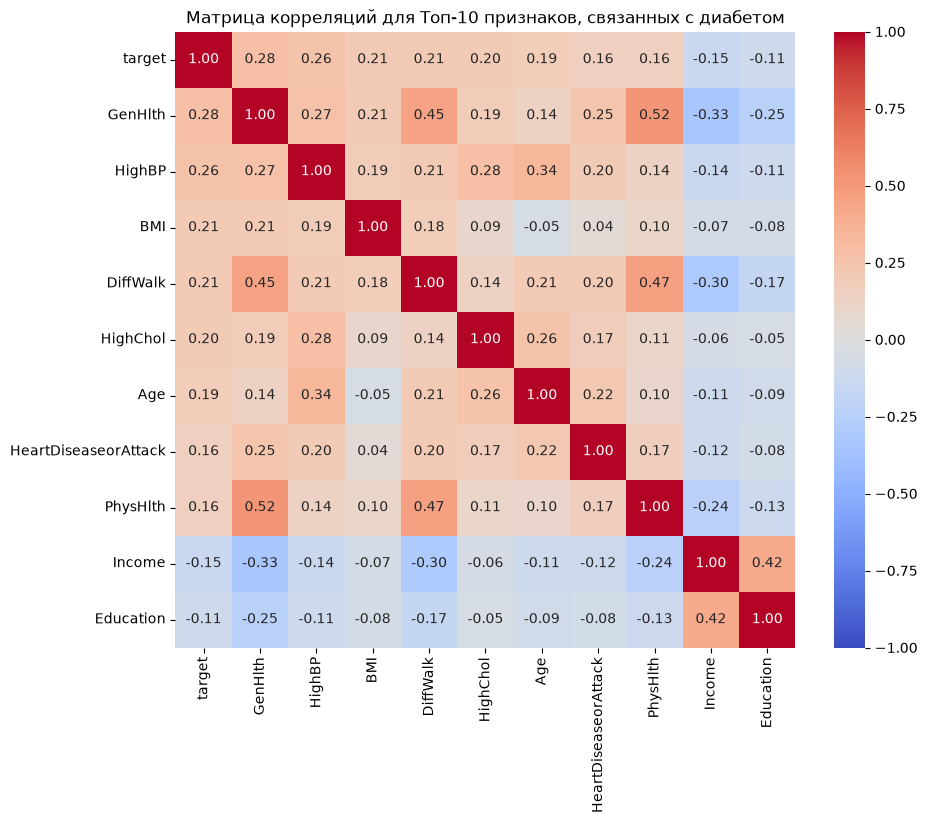

In [4]:
train_df = Xtr_df.copy()
train_df['target'] = ytr_b
full_corr = train_df.corr(method='pearson')

top_features = full_corr['target'].abs().sort_values(ascending=False).head(11).index

plt.figure(figsize=(10, 8))
sns.heatmap(full_corr.loc[top_features, top_features], annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Матрица корреляций для Топ-10 признаков, связанных с диабетом")
plt.show()

Среди всех факторов наибольшую прямую линейную корреляцию с наличием диабета демонстрируют:
1. GenHlth (Общее состояние здоровья): 0.28 — самый сильный фактор. Хуже субъективная оценка здоровья → выше вероятность диабета.
2. HighBP (Высокое кровяное давление): 0.26 — подтверждает сильную медицинческую связь между гипертонией и диабетом.
3. BMI (Индекс массы тела) и DiffWalk (Трудности при ходьбе): по 0.21 — лишний вес и сопутствующие физические ограничения линейно связаны с ростом заболеваемости.
4. HighChol (Высокий холестерин): 0.20 и Age (Возраст): 0.19.


In [ ]:
def best_threshold(y, p):
    
    # Находит порог (от 0.05 до 0.95), максимизирующий Balanced Accuracy.
    
    # Создаем сетку порогов
    ths = np.arange(0.05, 0.951, 0.01)
    
    # Превращаем одномерный массив вероятностей p в матрицу предсказаний размера
    # Каждая строка соответствует своему порогу
    preds = (p >= ths[:, None]).astype(int)
    
    # Считаем сбалансированную точность для каждого порога
    scores = [balanced_accuracy_score(y, pred) for pred in preds]
    
    # Находим индекс максимального скора и возвращаем соответствующий порог
    best_idx = np.argmax(scores)
    return float(ths[best_idx])

def bin_metrics(y, p, thr):
    
    # Вычисляет комплекс основных метрик бинарной классификации для заданного порога отсечения вероятностей.
    
    # Бинаризуем вероятности по выбранному порогу
    pred = (p >= thr).astype(int)
    
    metrics = {
        "Recall": recall_score(y, pred, zero_division=0),
        "Precision": precision_score(y, pred, zero_division=0),
        "BalancedAcc": balanced_accuracy_score(y, pred),
        "ROC_AUC": roc_auc_score(y, p),
        "F1": f1_score(y, pred, zero_division=0)
    }
    
    return metrics

def plot_histories(hist_dict, title):
    # Рисует кривые обучения (train/val loss) для каждой модели из hist_dict.

    names = list(hist_dict)
    n = len(names)
    ncols = min(3, n)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.2 * nrows), squeeze=False)

    for ax in axes.ravel():          # спрятать лишние оси
        ax.set_visible(False)

    for ax, name in zip(axes.ravel(), names):
        h = hist_dict[name]
        ep = range(1, len(h["loss"]) + 1)
        ax.plot(ep, h["loss"], label="train")
        ax.plot(ep, h["val_loss"], label="validation")
        ax.set_title(name)
        ax.set_xlabel("Эпоха"); ax.set_ylabel("Loss")
        ax.legend(); ax.grid(alpha=0.3)
        ax.set_visible(True)

    fig.suptitle(title, fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

def build_mlp(cfg, input_dim, task, n_classes=None):
    reg = regularizers.l2(cfg["l2"]) if cfg.get("l2", 0) > 0 else None
    
    model = keras.Sequential([layers.Input(shape=(input_dim,))])
    for units in cfg["hidden"]:
        model.add(layers.Dense(units, activation=cfg["act"], kernel_regularizer=reg))
        if cfg.get("dropout", 0) > 0:
            model.add(layers.Dropout(cfg["dropout"]))
            
    if task == "regression":
        model.add(layers.Dense(1))
        loss = "mse"
    elif task == "binary":
        model.add(layers.Dense(1, activation="sigmoid"))
        loss = "binary_crossentropy"
    elif task == "multiclass":
        if n_classes is None:
            raise ValueError("Параметр 'n_classes' обязателен для мультиклассовой классификации (task='multiclass').")
        model.add(layers.Dense(n_classes, activation="softmax"))
        loss = "sparse_categorical_crossentropy"
    else:
        raise ValueError(f"Неизвестный тип задачи: '{task}'. Допустимые: 'regression', 'binary', 'multiclass'.")
        
    lr = cfg["lr"]
    opt_name = cfg["opt"].lower()
    
    if opt_name == "adam":
        optimizer = keras.optimizers.Adam(learning_rate=lr)
    elif opt_name == "rmsprop":
        optimizer = keras.optimizers.RMSprop(learning_rate=lr)
    elif opt_name == "sgd":
        optimizer = keras.optimizers.SGD(learning_rate=lr, momentum=0.9)
    else:
        raise ValueError(f"Неизвестный оптимизатор: '{opt_name}'. Допустимые: 'adam', 'rmsprop', 'sgd'.")
        
    model.compile(optimizer=optimizer, loss=loss)
    
    return model

In [6]:
bin_rows = []
bin_hist, bin_models, bin_probs = {}, {}, {}

# Базовая модель: предсказывает вероятности классов по их долям в train
dummy = DummyClassifier(strategy="prior")
history = dummy.fit(Xtr_b, ytr_b)

pva = dummy.predict_proba(Xva_b)[:, 1]
pte = dummy.predict_proba(Xte_b)[:, 1]
thr = 0.5

bin_models["Dummy (prior)"] = dummy
bin_probs["Dummy (prior)"] = (pva, pte, thr)
bin_rows.append(dict(
    Модель="Dummy (prior)",
    Порог=thr,
    Эпох=np.nan,
    **{"Val ROC_AUC": roc_auc_score(yva_b, pva)},
    **bin_metrics(yte_b, pte, thr)
))

bin_df = pd.DataFrame(bin_rows)

print(classification_report(yte_b, (pte >= thr).astype(int), digits=4))
keras.backend.clear_session()

print("\n" + bin_df.round(4).to_string(index=False))

d:\Code\GitHubRep\neural_networks_labs\lab1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Code\GitHubRep\neural_networks_labs\lab1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Code\GitHubRep\neural_networks_labs\lab1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier,

              precision    recall  f1-score   support

           0     0.8271    1.0000    0.9054     28509
           1     0.0000    0.0000    0.0000      5959

    accuracy                         0.8271     34468
   macro avg     0.4136    0.5000    0.4527     34468
weighted avg     0.6841    0.8271    0.7489     34468



       Модель  Порог  Эпох  Val ROC_AUC  Recall  Precision  BalancedAcc  ROC_AUC  F1
Dummy (prior)    0.5   NaN          0.5     0.0        0.0          0.5      0.5 0.0


* Class 1 (Precision: 0.00, Recall: 0.00, F1-score: 0.00): Модель не смогла найти ни одного человека с диабетом (Recall = 0) и ни разу не сделала такое предсказание (Precision = 0).
* Class 0 (Recall: 1.0000): Модель успешно нашла 100% здоровых людей, так как записала в здоровые вообще весь датасет.

При высокой точности (82.7%) модель абсолютно бесполезна. Она просто угадывает класс 0 для всех подряд за счет его численного превосходства. 

In [7]:
cfg_mlp1 = dict(name="MLP-1", hidden=[32], act="relu", opt="adam", lr=1e-3, batch=512, dropout=0.0, l2=0.0)

model_mlp1 = build_mlp(
    cfg=cfg_mlp1,
    input_dim=Xtr_b.shape[1],
    task="binary"
)

es = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)
h = model_mlp1.fit(
    Xtr_b, ytr_b,
    validation_data=(Xva_b, yva_b),
    epochs=60,
    batch_size=cfg_mlp1["batch"],
    callbacks=[es],
    class_weight=cw,
    verbose=0
)

pva = model_mlp1.predict(Xva_b, verbose=0).ravel()
pte = model_mlp1.predict(Xte_b, verbose=0).ravel()
thr = best_threshold(yva_b, pva)

bin_hist[cfg_mlp1["name"]] = h.history
bin_models[cfg_mlp1["name"]] = model_mlp1
bin_probs[cfg_mlp1["name"]] = (pva, pte, thr)

bin_rows.append(dict(
    Модель=cfg_mlp1["name"],
    Порог=round(thr, 2),
    Эпох=int(np.argmin(h.history["val_loss"])) + 1,
    **{"Val ROC_AUC": roc_auc_score(yva_b, pva)},
    **bin_metrics(yte_b, pte, thr)
))

print(classification_report(yte_b, (pte >= thr).astype(int), digits=4))
keras.backend.clear_session()

bin_df = pd.concat([bin_df, pd.DataFrame([bin_rows[-1]])], ignore_index=True)
print("\n" + bin_df.round(4).to_string(index=False))

              precision    recall  f1-score   support

           0     0.9323    0.7120    0.8074     28509
           1     0.3533    0.7528    0.4809      5959

    accuracy                         0.7190     34468
   macro avg     0.6428    0.7324    0.6442     34468
weighted avg     0.8322    0.7190    0.7510     34468


       Модель  Порог  Эпох  Val ROC_AUC  Recall  Precision  BalancedAcc  ROC_AUC     F1
Dummy (prior)   0.50   NaN       0.5000  0.0000     0.0000       0.5000   0.5000 0.0000
        MLP-1   0.53  14.0       0.8132  0.7528     0.3533       0.7324   0.8116 0.4809


* Класс Диабет: Recall подскочил
    Это главное достижение. Базовая модель пропускала абсолютно всех больных (Recall = 0). Теперь нейросеть успешно находит ~ 75% всех людей с диабетом в тестовой выборке. В медицинских задачах высокий Recall — самый критичный показатель, так как пропустить болезнь гораздо опаснее, чем ошибиться и отправить здорового на дообследование.
* Класс 1 (Диабет) Precision ~ 34%:
    Невысокая точность означает, что среди всех, кого модель пометила как «болен», реальный диабет подтвердится примерно у трети (34%). Это ожидаемая плата за высокий Recall в условиях дисбаланса: модель стала более «чувствительной» и склонна перестраховываться.
* Macro Avg F1-score увеличился.
    Это показывает, что качество распознавания обоих классов в среднем значительно выросло.
* Accuracy снизилась. 
    И это абсолютно нормально. Падение общей точности произошло из-за того, что часть здоровых людей (класс 0) модель теперь ошибочно относит к первому классу (их Recall снизился). Но зато теперь модель действительно работает, а не просто константно выдает нули.

In [8]:
cfg_mlp2 = dict(name="MLP-2", hidden=[64, 32], act="relu", opt="adam", lr=1e-3, batch=512, dropout=0.2, l2=0.0)

model_mlp2 = build_mlp(
    cfg=cfg_mlp2,
    input_dim=Xtr_b.shape[1],
    task="binary"
)

h_mlp2 = model_mlp2.fit(
    Xtr_b, ytr_b,
    validation_data=(Xva_b, yva_b),
    epochs=60,
    batch_size=cfg_mlp2["batch"],
    callbacks=[es],
    class_weight=cw,
    verbose=0
)

pva_mlp2 = model_mlp2.predict(Xva_b, verbose=0).ravel()
pte_mlp2 = model_mlp2.predict(Xte_b, verbose=0).ravel()
thr_mlp2 = best_threshold(yva_b, pva_mlp2)

bin_hist[cfg_mlp2["name"]] = h_mlp2.history
bin_models[cfg_mlp2["name"]] = model_mlp2
bin_probs[cfg_mlp2["name"]] = (pva_mlp2, pte_mlp2, thr_mlp2)

bin_rows.append(dict(
    Модель=cfg_mlp2["name"],
    Порог=round(thr_mlp2, 2),
    Эпох=int(np.argmin(h_mlp2.history["val_loss"])) + 1,
    **{"Val ROC_AUC": roc_auc_score(yva_b, pva_mlp2)},
    **bin_metrics(yte_b, pte_mlp2, thr_mlp2)
))

print(classification_report(yte_b, (pte_mlp2 >= thr_mlp2).astype(int), digits=4))
keras.backend.clear_session()

bin_df = pd.concat([bin_df, pd.DataFrame([bin_rows[-1]])], ignore_index=True)
print("\n" + bin_df.round(4).to_string(index=False))

              precision    recall  f1-score   support

           0     0.9368    0.6875    0.7930     28509
           1     0.3423    0.7780    0.4754      5959

    accuracy                         0.7032     34468
   macro avg     0.6395    0.7328    0.6342     34468
weighted avg     0.8340    0.7032    0.7381     34468


       Модель  Порог  Эпох  Val ROC_AUC  Recall  Precision  BalancedAcc  ROC_AUC     F1
Dummy (prior)   0.50   NaN       0.5000  0.0000     0.0000       0.5000   0.5000 0.0000
        MLP-1   0.53  14.0       0.8132  0.7528     0.3533       0.7324   0.8116 0.4809
        MLP-2   0.50  15.0       0.8136  0.7780     0.3423       0.7328   0.8115 0.4754


* Класс Диабет: 
    Recall (0.7780): Полнота незначительно снизилась по сравнению с MLP-1 (было 0.7822), однако модель по-прежнему уверенно находит почти 78% всех больных в тестовой выборке.
    Precision (0.3423): Точность немного выросла (было 0.3416). Модель стала делать чуть меньше ложноположительных предсказаний.
* Класс Здоровые:
    Recall (0.6875): Способность правильно определять здоровых людей выросла (было 0.6848). Сеть стала чуть лучше отсеивать ложные тревоги.
* Общая точность (Accuracy) поднялась до 0.7032 

In [9]:
cfg_mlp3 = dict(name="MLP-3", hidden=[128, 64, 32], act="relu", opt="adam", lr=1e-3, batch=512, dropout=0.3, l2=1e-4)

model_mlp3 = build_mlp(
    cfg=cfg_mlp3,
    input_dim=Xtr_b.shape[1],
    task="binary"
)

h_mlp3 = model_mlp3.fit(
    Xtr_b, ytr_b,
    validation_data=(Xva_b, yva_b),
    epochs=60,
    batch_size=cfg_mlp3["batch"],
    callbacks=[es],
    class_weight=cw,
    verbose=0
)

# Предсказания и оптимизация порога на валидационной выборке
pva_mlp3 = model_mlp3.predict(Xva_b, verbose=0).ravel()
pte_mlp3 = model_mlp3.predict(Xte_b, verbose=0).ravel()
thr_mlp3 = best_threshold(yva_b, pva_mlp3)

# Сохраняем результаты работы MLP-3
bin_hist[cfg_mlp3["name"]] = h_mlp3.history
bin_models[cfg_mlp3["name"]] = model_mlp3
bin_probs[cfg_mlp3["name"]] = (pva_mlp3, pte_mlp3, thr_mlp3)

bin_rows.append(dict(
    Модель=cfg_mlp3["name"],
    Порог=round(thr_mlp3, 2),
    Эпох=int(np.argmin(h_mlp3.history["val_loss"])) + 1,
    **{"Val ROC_AUC": roc_auc_score(yva_b, pva_mlp3)},
    **bin_metrics(yte_b, pte_mlp3, thr_mlp3)
))

print(classification_report(yte_b, (pte_mlp3 >= thr_mlp3).astype(int), digits=4))
keras.backend.clear_session()

print("\n=== Итоговая таблица сравнения моделей ===")
bin_df = pd.concat([bin_df, pd.DataFrame([bin_rows[-1]])], ignore_index=True)
print("\n" + bin_df.round(4).to_string(index=False))

              precision    recall  f1-score   support

           0     0.9358    0.6942    0.7971     28509
           1     0.3455    0.7723    0.4774      5959

    accuracy                         0.7077     34468
   macro avg     0.6407    0.7333    0.6373     34468
weighted avg     0.8338    0.7077    0.7419     34468


=== Итоговая таблица сравнения моделей ===

       Модель  Порог  Эпох  Val ROC_AUC  Recall  Precision  BalancedAcc  ROC_AUC     F1
Dummy (prior)   0.50   NaN       0.5000  0.0000     0.0000       0.5000   0.5000 0.0000
        MLP-1   0.53  14.0       0.8132  0.7528     0.3533       0.7324   0.8116 0.4809
        MLP-2   0.50  15.0       0.8136  0.7780     0.3423       0.7328   0.8115 0.4754
        MLP-3   0.52   7.0       0.8131  0.7723     0.3455       0.7333   0.8113 0.4774


* Максимальный Macro Avg F1-score : Это самый высокий показатель баланса точности и полноты среди всех моделей (MLP-1: 0.6335, MLP-2: 0.6342).
* Рост Precision для класса 1 (0.3455): Точность обнаружения диабета достигла пика. Модель стала делать меньше ложных срабатываний, при этом её Recall остался на высоком уровне (0.7723) — она стабильно находит более 77% больных.
* Улучшение классификации класса 0 (Recall: 0.6942): Сеть стала заметно лучше распознавать здоровых людей, благодаря чему общая точность Accuracy поднялась до 0.7077.

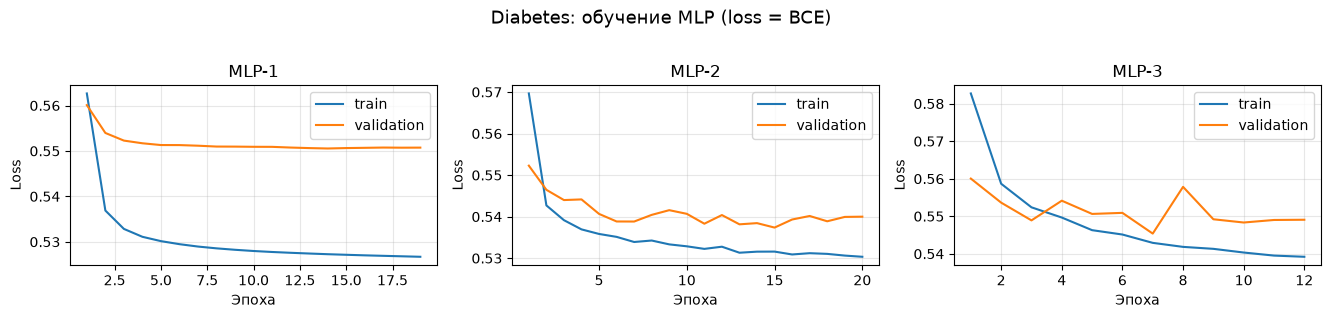

In [10]:
plot_histories(bin_hist, "Diabetes: обучение MLP (loss = BCE)")

Внедрение Dropout и L2-регуляризации в моделях MLP-2 и MLP-3 полностью оправдало себя. Они смогли устранить застой (плато) валидационной ошибки, характерный для простой модели MLP-1, и обеспечили эффективный контроль переобучения на большом и несбалансированном датасете.

Лучшая модель по Val ROC-AUC: MLP-2, порог = 0.50


Text(0.5, 1.0, 'ROC-кривые (test)')

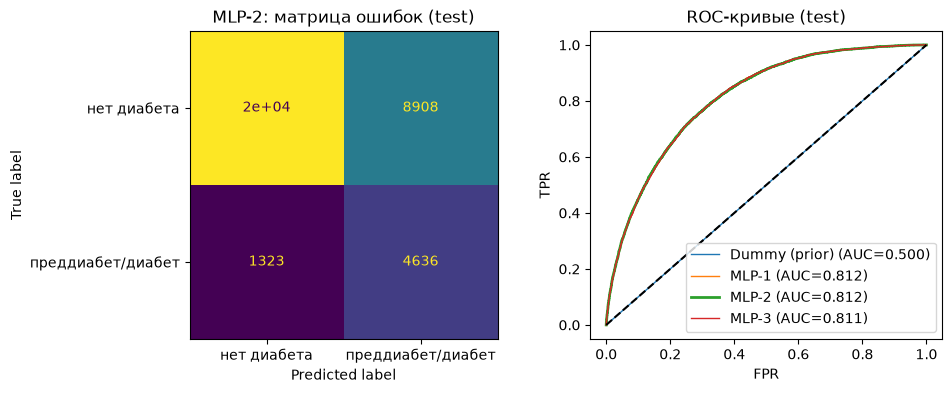

In [11]:
nn = bin_df[bin_df["Модель"].str.startswith("MLP")]
bname = nn.loc[nn["Val ROC_AUC"].idxmax(), "Модель"]
pva, pte, thr = bin_probs[bname]
print(f"Лучшая модель по Val ROC-AUC: {bname}, порог = {thr:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(yte_b, (pte >= thr).astype(int)), display_labels=["нет диабета", "преддиабет/диабет"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title(f"{bname}: матрица ошибок (test)")

for n_, (_, pt_, _) in bin_probs.items():
    f, t, _ = roc_curve(yte_b, pt_); ax[1].plot(f, t, label=f"{n_} (AUC={roc_auc_score(yte_b, pt_):.3f})", lw=2 if n_ == bname else 1)
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend(); ax[1].set_title("ROC-кривые (test)")


Матрица построена на тестовой выборке и наглядно раскрывает компромисс между ошибками:
* True Negative (2e+04 ≈ 19 601): Модель успешно определила большинство здоровых людей («нет диабета»).
* True Positive (4 636): Модель правильно выявила 4 636 пациентов с преддиабетом или диабетом. Это и дает высокий Recall = 77.8% (\(4636 / (4636 + 1323)\)).
* False Negative (1 323) [Пропуск цели]: Всего 1 323 больных человека ошибочно классифицированы как здоровые. Для медицинской задачи минимизация этого числа — главный приоритет.
* False Positive (8 908) [Ложная тревога]: Довольно большое число здоровых людей модель направила на «дообследование». Именно этот столбец обуславливает невысокий Precision = 34.2% (\(4636 / (4636 + 8908)\)). Модель сознательно перестраховывается из-за смещения весов (class_weight)

График справа показывает способность моделей ранжировать объекты по степени риска заболевания:
* Базовая модель (Dummy): Идет строго по пунктирной диагонали с AUC = 0.500, что соответствует абсолютно случайному угадыванию (как подбрасывание монетки).
* Нейросети (MLP-1, MLP-2, MLP-3): Все три кривые практически слились в одну идеальную дугу, значительно удаленную от диагонали.

## 2. Многоклассовая классификация: Body Performance
Классы A, B, C, D кодируются числами; признак `gender` — категориальный (One-Hot).

In [26]:
body = pd.read_csv("bodyPerformance.csv")

print("--- 1. Первые 5 строк датасета ---")
display(body.head())

print("--- 2. Информация и пропущенные значения ---")
print("Размер:", body.shape, "| пропусков:", int(body.isna().sum().sum()), "| полных дубликатов:", int(body.duplicated().sum()))
print("\nИсходное распределение class:\n", body["class"].value_counts().sort_index())

print("--- 3. Описательные статистики ---")
display(body.describe().T)

vc = body["class"].value_counts().sort_index()
print("\nКлассы:\n", pd.DataFrame({"n": vc, "доля": (vc / len(body)).round(4)}))

print("\n--- 4. Распределение целевой переменной (target) ---")
counts = body["class"].value_counts()
percentages = body["class"].value_counts(normalize=True) * 100
target_df = pd.DataFrame({'Количество': counts, 'Процент (%)': percentages})
display(target_df)

le = LabelEncoder()
y_m = le.fit_transform(body["class"])
CLASSES = list(le.classes_)
K = len(CLASSES)
X = body.drop(columns=["class"])


Xtr_df, Xva_df, Xte_df, ytr_m, yva_m, yte_m = split_dataset(X, y_m, stratify=True)

# Затем масштабируем/предобрабатываем признаки
Xtr_m, Xva_m, Xte_m, _ = preprocess_datasets(Xtr_df, Xva_df, Xte_df)


print("\n--- 5. Контроль разбиения и веса классов ---")

print("Распределение классов в train:", np.bincount(ytr_m) / len(ytr_m))

classes_in_train = np.unique(ytr_m)
weights = compute_class_weight(class_weight='balanced', classes=classes_in_train, y=ytr_m)
cw = dict(zip(classes_in_train, weights))

print("class_weight:", {k: round(v, 3) for k, v in cw.items()})


--- 1. Первые 5 строк датасета ---


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B


--- 2. Информация и пропущенные значения ---
Размер: (13393, 12) | пропусков: 0 | полных дубликатов: 1

Исходное распределение class:
 class
A    3348
B    3347
C    3349
D    3349
Name: count, dtype: int64
--- 3. Описательные статистики ---


,count,mean,std,min,25%,50%,75%,max
age,13393.0,36.775106,13.625639,21.0,25.0,32.0,48.0,64.0
height_cm,13393.0,168.559807,8.426583,125.0,162.4,169.2,174.8,193.8
weight_kg,13393.0,67.447316,11.949666,26.3,58.2,67.4,75.3,138.1
body fat_%,13393.0,23.240165,7.256844,3.0,18.0,22.8,28.0,78.4
diastolic,13393.0,78.796842,10.742033,0.0,71.0,79.0,86.0,156.2
systolic,13393.0,130.234817,14.713954,0.0,120.0,130.0,141.0,201.0
gripForce,13393.0,36.963877,10.624864,0.0,27.5,37.9,45.2,70.5
sit and bend forward_cm,13393.0,15.209268,8.456677,-25.0,10.9,16.2,20.7,213.0
sit-ups counts,13393.0,39.771224,14.276698,0.0,30.0,41.0,50.0,80.0
broad jump_cm,13393.0,190.129627,39.868000,0.0,162.0,193.0,221.0,303.0



Классы:
           n    доля
class              
A      3348  0.2500
B      3347  0.2499
C      3349  0.2501
D      3349  0.2501

--- 4. Распределение целевой переменной (target) ---


,Количество,Процент (%)
class,,
C,3349,25.005600
D,3349,25.005600
A,3348,24.998133
B,3347,24.990667


Предобработка завершена:
  Числовых признаков: 10
  Категориальных признаков: 1
  Итоговая размерность матрицы (кол-во колонок): 12

--- 5. Контроль разбиения и веса классов ---
Распределение классов в train: [0.25002667 0.24992    0.25002667 0.25002667]
class_weight: {np.int64(0): np.float64(1.0), np.int64(1): np.float64(1.0), np.int64(2): np.float64(1.0), np.int64(3): np.float64(1.0)}


| Имя признака | Перевод названия | Тип данных | Описание и диапазон значений |
| :--- | :--- | :---: | :--- |
| **class** | Класс физ. развития | Категориальный | **Целевой признак (Target)**. 4 уровня подготовки: **A** (лучший), **B**, **C**, **D** (худший). Перед подачей в MLP кодируется в числа `0, 1, 2, 3`. |
| **age** | Возраст | Числовой | Возраст респондента в годах (от 21 до 64 лет). Среднее значение — 36.8 лет. |
| **gender** | Пол | Категориальный | Пол респондента: `M` (мужской) или `F` (женский). Преобразуется в числовой вид через кодирование. |
| **height_cm** | Рост (см) | Числовой | Рост в сантиметрах (от 125.0 до 193.8 см). |
| **weight_kg** | Вес (кг) | Числовой | Масса тела в килограммах (от 26.3 до 138.1 кг). |
| **body fat_%** | Процент жира | Числовой | Процент содержания жировой ткани в организме (от 3.0% до 78.4%). Ключевой маркер состава тела. |
| **diastolic** | Диастолическое АД | Числовой | «Нижнее» артериальное давление (мм рт. ст.). *В данных содержатся аномальные нулевые значения.* |
| **systolic** | Систолическое АД | Числовой | «Верхнее» артериальное давление (мм рт. ст.). Среднее значение по выборке — 130.2 мм рт. ст. |
| **gripForce** | Сила сжатия кисти | Числовой | Результат кистевой динамометрии в килограммах (от 0.0 до 70.5 кг). Измеряет абсолютную силу мышц рук. |
| **sit and bend forward_cm** | Наклон вперед сидя | Числовой | Тест на гибкость позвоночника (в см). Отрицательные значения (до -25.0) нормальны. *Присутствует выброс 213.0 см.* |
| **sit-ups counts** | Подъемы туловища | Числовой | Количество повторений упражнения на пресс за фиксированное время (от 0 до 80 раз). Измеряет выносливость. |
| **broad jump_cm** | Прыжок в длину | Числовой | Длина прыжка с места в сантиметрах (от 0 до 303 см). Характеризует взрывную силу ног. |


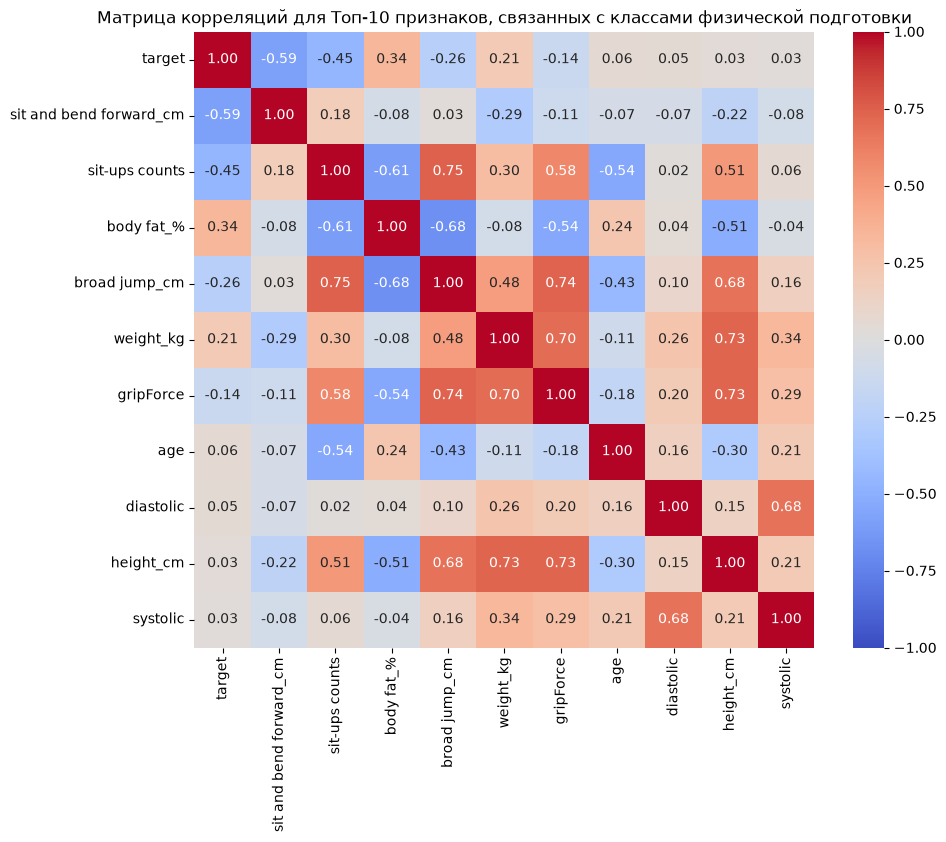

In [13]:
train_df = Xtr_df.copy()
train_df['target'] = ytr_m
full_corr = train_df.corr(method='pearson', numeric_only=True)

top_features = full_corr['target'].abs().sort_values(ascending=False).head(11).index

plt.figure(figsize=(10, 8))
sns.heatmap(full_corr.loc[top_features, top_features], annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Матрица корреляций для Топ-10 признаков, связанных с классами физической подготовки")
plt.show()

#### 1. Взаимосвязь признаков с целевой переменной (`target`)
Целевая переменная демонстрирует сильную и умеренную линейную связь с ключевыми спортивными показателями:
*   **`sit and bend forward_cm` (Наклон вперед сидя): `-0.59`** — наиболее сильная обратная корреляция. Это указывает на то, что с улучшением гибкости (увеличением значения в см) числовая метка класса снижается. Поскольку наилучший класс физической формы — **A** (кодируется как `0`), отрицательный коэффициент подтверждает, что развитая гибкость напрямую связана с более высоким уровнем физического развития.
*   **`sit-ups counts` (Подъемы туловища): `-0.45`** — сильная обратная связь. Чем больше повторений на пресс выполняет человек, тем ближе он к лучшему классу физподготовки (ближе к `0`).
*   **`body fat_%` (Процент жира): `0.34`** — прямая корреляция. Рост проценты жира в организме линейно связан с ухудшением класса физического развития (сдвиг в сторону классов **C** и **D**, кодируемых как `2` и `3`).
*   **`broad jump_cm` (Прыжок в длину): `-0.26`** и **`weight_kg` (Вес): `0.21`** — взрывная сила ног и оптимальный вес также вносят весомый вклад в общую оценку.

Такие признаки, как **`age` (0.06)**, **`diastolic` (0.05)**, **`height_cm` (0.03)** и **`systolic` (0.03)**, практически не имеют прямой *линейной* связи с итоговым классом. Тем не менее, они важны для нейросети, так как влияют на другие показатели нелинейно.

#### 2. Анализ мультиколлинеарности и сильных взаимосвязей
В отличие от предыдущего датасета, здесь присутствует группа сильно взаимосвязанных признаков (коэффициенты корреляции близки к критическим или превышают `0.70`). Это объясняется физиологическими особенностями человека:
*   **Связь веса, роста и силы:** Наблюдается выраженная коллинеарность между парами `weight_kg` и `height_cm` (`0.73`), `gripForce` и `weight_kg` (`0.70`), а также `gripForce` и `height_cm` (`0.73`). Более высокие и крупные люди обладают большей абсолютной силой сжатия кисти.
*   **Связь прыжка в длину и физических параметров:** Признак `broad jump_cm` сильно коррелирует с силой кисти `gripForce` (`0.74`) и количеством подъемов туловища `sit-ups counts` (`0.75`), но имеет выраженную обратную связь с процентом жира `body fat_%` (`-0.68`). Это показывает, что прыгучесть (взрывная сила) напрямую зависит от общей мышечной массы и снижается при избыточном весе.
*   **Показатели давления:** Давление `diastolic` и `systolic` ожидаемо связано между собой (`0.68`).

#### Вывод для проектирования MLP:
Наличие сильных корреляций (до `0.75`) между антропометрическими параметрами и спортивными результатами указывает на избыточность некоторых линейных признаков. Полносвязная нейронная сеть (MLP) за счёт скрытых слоёв и нелинейных функций активации (`ReLU`) способна эффективно комбинировать эти коррелирующие факторы, извлекая из них скрытые паттерны (например, вычисляя условное соотношение веса к силе).


In [28]:
def multi_eval(y, proba, k):
    pred = proba.argmax(1)
    rep = classification_report(y, pred, target_names=CLASSES, output_dict=True, zero_division=0)
    Y = label_binarize(y, classes=list(range(k)))
    aucs = [roc_auc_score(Y[:, i], proba[:, i]) for i in range(k)]          # One-vs-Rest
    return dict(rep=rep, bal=balanced_accuracy_score(y, pred), aucs=aucs, macro_auc=float(np.mean(aucs)), acc=accuracy_score(y, pred), pred=pred)

mc = {}
mc_val = {}
mc_hist = {}
mc_proba = {}
mc_models = {}

rows = []

dummy_mc = DummyClassifier(strategy="prior")
history = dummy_mc.fit(Xtr_m, ytr_m)

proba_va = dummy_mc.predict_proba(Xva_m)
proba_te = dummy_mc.predict_proba(Xte_m)

mc_models["Dummy (prior)"] = dummy_mc
mc_val["Dummy (prior)"] = multi_eval(yva_m, proba_va, K)
mc["Dummy (prior)"] = multi_eval(yte_m, proba_te, K)
mc_proba["Dummy (prior)"] = proba_te

rows.append(
    {
        "Модель": n,
        "Val BalAcc": mc_val[n]["bal"],
        "Test Accuracy": r["acc"], 
        "Test BalAcc": r["bal"],
        "Test macro ROC-AUC (OvR)": r["macro_auc"],
        "Test macro F1": r["rep"]["macro avg"]["f1-score"]
    } 
    for n, r in mc.items()
)

print(classification_report(yte_m, mc["Dummy (prior)"]["pred"], target_names=CLASSES, digits=4))
keras.backend.clear_session()

d:\Code\GitHubRep\neural_networks_labs\lab1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Code\GitHubRep\neural_networks_labs\lab1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Code\GitHubRep\neural_networks_labs\lab1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier,

              precision    recall  f1-score   support

           A     0.2499    1.0000    0.3998       502
           B     0.0000    0.0000    0.0000       502
           C     0.0000    0.0000    0.0000       503
           D     0.0000    0.0000    0.0000       502

    accuracy                         0.2499      2009
   macro avg     0.0625    0.2500    0.1000      2009
weighted avg     0.0624    0.2499    0.0999      2009



In [ ]:

for cfg in CFGS:
    model = build_mlp(cfg, Xtr_m.shape[1], "multiclass", n_classes=K)
    
    es = keras.callbacks.EarlyStopping(
        monitor="val_loss", 
        patience=15,
        restore_best_weights=True, 
        verbose=0
    )
    
    h = model.fit(
        Xtr_m, ytr_m, 
        validation_data=(Xva_m, yva_m),
        epochs=200, 
        batch_size=64, 
        callbacks=[es], 
        verbose=0
    )

    # Генерация предсказаний БЕЗ дублирования вызовов
    preds_va = model.predict(Xva_m, verbose=0)
    preds_te = model.predict(Xte_m, verbose=0)
    
    mc_hist[cfg["name"]] = h.history
    mc_models[cfg["name"]] = model
    mc_proba[cfg["name"]] = preds_te
    
    mc_val[cfg["name"]] = multi_eval(yva_m, preds_va, K)
    mc[cfg["name"]] = multi_eval(yte_m, preds_te, K)
    
    print("[b]", cfg["name"], "готово")
    print(classification_report(yte_m, mc[cfg["name"]]["pred"], target_names=CLASSES, digits=4))
    keras.backend.clear_session()

summB = pd.DataFrame([dict(
    Модель=n,
    **{
        "Val BalAcc": mc_val[n]["bal"],
        "Test Accuracy": r["acc"], 
        "Test BalAcc": r["bal"],
        "Test macro ROC-AUC (OvR)": r["macro_auc"],
        "Test macro F1": r["rep"]["macro avg"]["f1-score"]
    }) for n, r in mc.items()
])

print(summB.round(4).to_string(index=False))

       Модель       Метрика      A      B      C      D  Macro avg  Weighted avg
Dummy (prior)     precision 0.2499 0.0000 0.0000 0.0000     0.0625        0.0624
Dummy (prior)        recall 1.0000 0.0000 0.0000 0.0000     0.2500        0.2499
Dummy (prior)      f1-score 0.3998 0.0000 0.0000 0.0000     0.1000        0.0999
Dummy (prior) ROC-AUC (OvR) 0.5000 0.5000 0.5000 0.5000     0.5000           NaN
        MLP-1     precision 0.6896 0.6580 0.7394 0.9237     0.7527        0.7527
        MLP-1        recall 0.8984 0.5558 0.6938 0.8446     0.7482        0.7481
        MLP-1      f1-score 0.7803 0.6026 0.7159 0.8824     0.7453        0.7453
        MLP-1 ROC-AUC (OvR) 0.9485 0.8770 0.8973 0.9618     0.9212           NaN
        MLP-2     precision 0.7039 0.6504 0.7408 0.9441     0.7598        0.7598
        MLP-2        recall 0.9044 0.6116 0.6819 0.8068     0.7512        0.7511
        MLP-2      f1-score 0.7916 0.6304 0.7101 0.8700     0.7505        0.7505
        MLP-2 ROC-AUC (OvR) 

C:\Users\Admin\AppData\Local\Temp\ipykernel_20240\1622875732.py:21: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  tabB.rename(columns={c: CLASSES[c] for c in range(K)}, inplace=True)


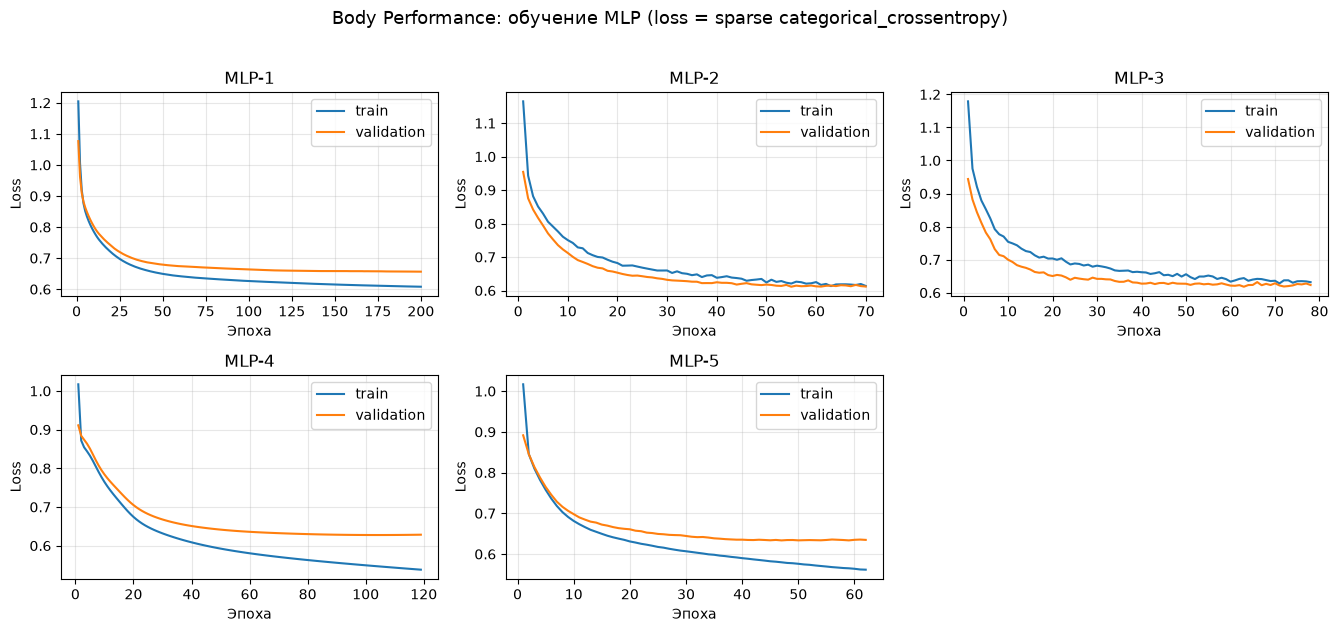

In [15]:
rows = []
for n, r in mc.items():
    for met in ["precision", "recall", "f1-score"]:
        rows.append({
            "Модель": n,
            "Метрика": met,
            **{c: r["rep"][CLASSES[c]][met] for c in range(K)},
            "Macro avg": r["rep"]["macro avg"][met],
            "Weighted avg": r["rep"]["weighted avg"][met]
        })

    rows.append({
        "Модель": n,
        "Метрика": "ROC-AUC (OvR)",
        **{c: a for c, a in zip(range(K), r["aucs"])},
        "Macro avg": r["macro_auc"],
        "Weighted avg": np.nan
    })

tabB = pd.DataFrame(rows)
tabB.rename(columns={c: CLASSES[c] for c in range(K)}, inplace=True)
print(tabB.round(4).to_string(index=False))

plot_histories(
    mc_hist,
    "Body Performance: обучение MLP (loss = sparse categorical_crossentropy)"
)

Лучшая модель по Val Balanced Accuracy: MLP-3


Text(0.5, 1.0, 'MLP-3: ROC One-vs-Rest (test), macro AUC=0.929')

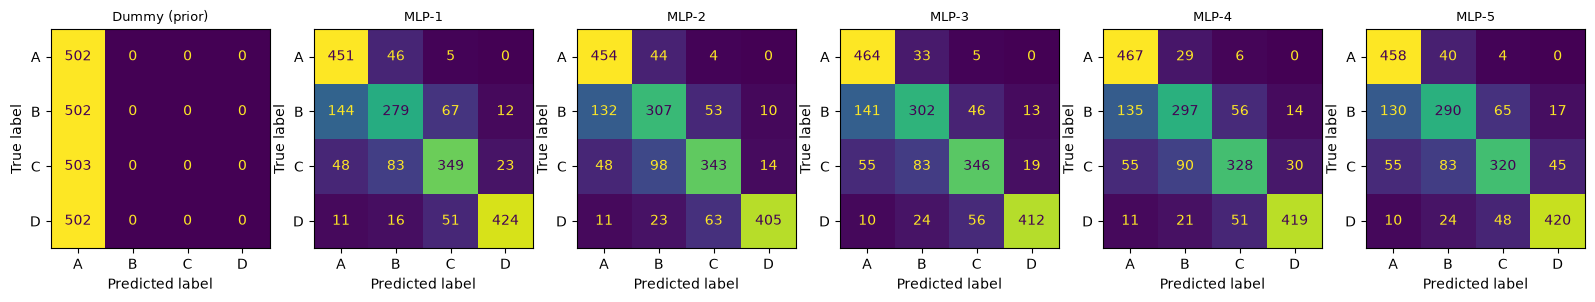

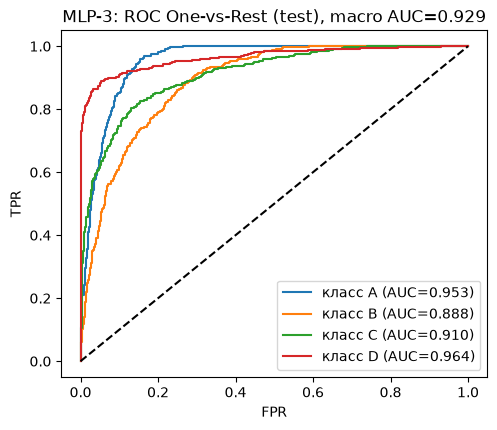

In [16]:
# Матрицы ошибок всех моделей
names = list(mc.keys()); fig, axs = plt.subplots(1, len(names), figsize=(3.3*len(names), 3.3))
for ax, n in zip(axs, names):
    ConfusionMatrixDisplay(confusion_matrix(yte_m, mc[n]["pred"]), display_labels=CLASSES).plot(ax=ax, colorbar=False); ax.set_title(n, fontsize=9)

# Лучшая модель по Val Balanced Accuracy и её ROC-кривые OvR
nn_names = [n for n in mc if n.startswith("MLP")]; mname = max(nn_names, key=lambda n: mc_val[n]["bal"])
print("Лучшая модель по Val Balanced Accuracy:", mname)
Y = label_binarize(yte_m, classes=list(range(K))); plt.figure(figsize=(5.5, 4.5))
for i, c in enumerate(CLASSES):
    f, t, _ = roc_curve(Y[:, i], mc_proba[mname][:, i]); plt.plot(f, t, label=f"класс {c} (AUC={mc[mname]['aucs'][i]:.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend(); plt.title(f"{mname}: ROC One-vs-Rest (test), macro AUC={mc[mname]['macro_auc']:.3f}")


## 3. Регрессия: Wine Quality (white), целевой признак `quality`

In [17]:
wine = pd.read_csv("winequality-white.csv", sep=";")
print("Размер:", wine.shape); print("\nТипы столбцов:\n", wine.dtypes.value_counts())
print("\nПропуски:", int(wine.isna().sum().sum()), "| Полных дубликатов строк:", int(wine.duplicated().sum()))
print("\nОписательная статистика целевого признака:\n", wine["quality"].describe().round(3))
print("\nРаспределение quality:\n", wine["quality"].value_counts().sort_index())


Размер: (4898, 12)

Типы столбцов:
 float64    11
int64       1
Name: count, dtype: int64

Пропуски: 0 | Полных дубликатов строк: 937

Описательная статистика целевого признака:
 count    4898.000
mean        5.878
std         0.886
min         3.000
25%         5.000
50%         6.000
75%         6.000
max         9.000
Name: quality, dtype: float64

Распределение quality:
 quality
3      20
4     163
5    1457
6    2198
7     880
8     175
9       5
Name: count, dtype: int64


После удаления дубликатов: (3961, 12)
Предобработка завершена:
  Числовых признаков: 11
  Категориальных признаков: 0
  Итоговая размерность матрицы (кол-во колонок): 11


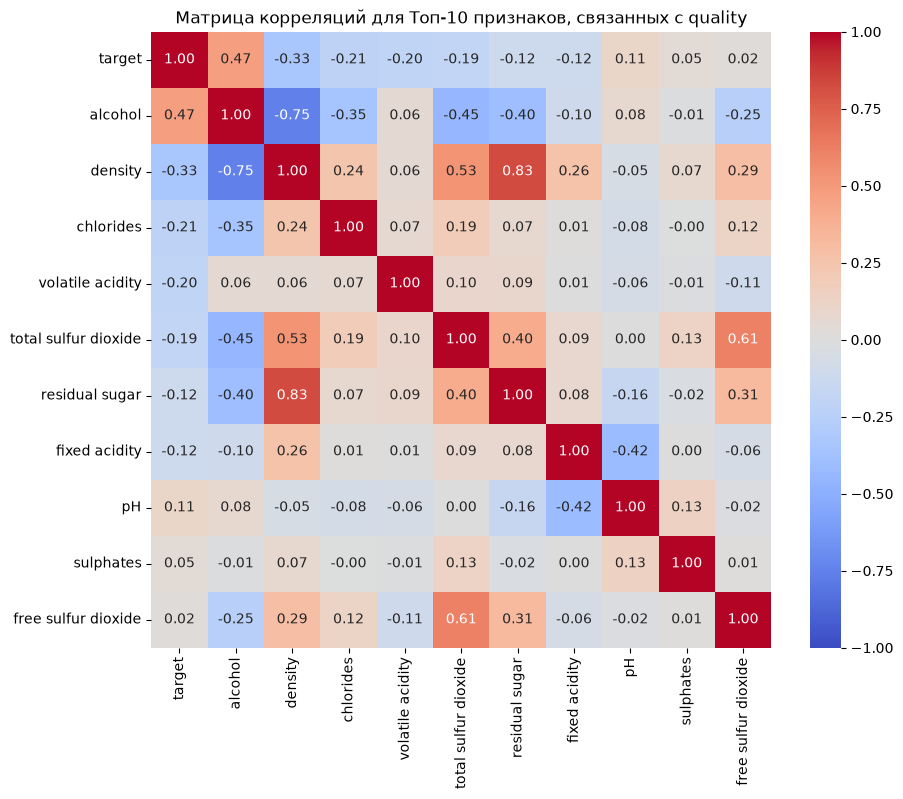

In [18]:
df = wine.drop_duplicates().reset_index(drop=True)
print("После удаления дубликатов:", df.shape)
X, y = df.drop(columns="quality"), df["quality"].astype("float32")
Xtr_df, Xva_df, Xte_df, ytr, yva, yte = split_dataset(X, y, stratify=False)
Xtr, Xva, Xte, _ = preprocess_datasets(Xtr_df, Xva_df, Xte_df)

train_df = Xtr_df.copy()
train_df['target'] = ytr
full_corr = train_df.corr(method='pearson', numeric_only=True)

top_features = full_corr['target'].abs().sort_values(ascending=False).head(11).index

plt.figure(figsize=(10, 8))
sns.heatmap(full_corr.loc[top_features, top_features], annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Матрица корреляций для Топ-10 признаков, связанных с quality")
plt.show()

**Утечка и дубликаты.** Идентификаторов и признаков, раскрывающих `quality`, в наборе нет — все 11 признаков физико-химические.
В белом вине много полных дубликатов строк; при случайном разбиении одна и та же строка могла бы попасть и в train, и в test, что завышает
метрики. Поэтому дубликаты удаляются **до разбиения** (`DROP_DUPLICATES = True`). Пропусков нет; импутация всё равно включена в конвейер.
Целевой признак не масштабируется (шкала 3–9), поэтому MSE/MAE сразу в исходных единицах.

In [19]:
def reg_metrics(y, p):
    return dict(
        MSE=mean_squared_error(y, p),
        MAE=mean_absolute_error(y, p),
        R2=r2_score(y, p)
    )

reg_rows, reg_hist, reg_models = [], {}, {}

# Базовая модель: всегда предсказывает среднее значение целевого признака на train
dummy_reg = DummyRegressor(strategy="mean")
dummy_reg.fit(Xtr, ytr)

P = {
    k: dummy_reg.predict(v)
    for k, v in dict(tr=Xtr, va=Xva, te=Xte).items()
}
reg_models["Dummy (mean)"] = dummy_reg

reg_rows.append(dict(
    Модель="Dummy (mean)",
    Эпох=np.nan,
    **{
        "Train MSE": reg_metrics(ytr, P["tr"])["MSE"],
        "Val MSE": reg_metrics(yva, P["va"])["MSE"],
        "Val R2": reg_metrics(yva, P["va"])["R2"]
    },
    **{f"Test {k}": v for k, v in reg_metrics(yte, P["te"]).items()}
))

for cfg0 in CFGS:
    cfg = cfg0
    model = build_mlp(cfg, Xtr.shape[1], "regression")

    es = callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True
    )
    h = model.fit(
        Xtr, ytr,
        validation_data=(Xva, yva),
        epochs=200,
        batch_size=cfg["batch"],
        callbacks=[es],
        verbose=0
    )

    reg_hist[cfg["name"]], reg_models[cfg["name"]] = h.history, model
    P = {
        k: model.predict(v, verbose=0).ravel()
        for k, v in dict(tr=Xtr, va=Xva, te=Xte).items()
    }

    reg_rows.append(dict(
        Модель=cfg["name"],
        Эпох=int(np.argmin(h.history["val_loss"])) + 1,
        **{
            "Train MSE": reg_metrics(ytr, P["tr"])["MSE"],
            "Val MSE": reg_metrics(yva, P["va"])["MSE"],
            "Val R2": reg_metrics(yva, P["va"])["R2"]
        },
        **{f"Test {k}": v for k, v in reg_metrics(yte, P["te"]).items()}
    ))

    print(
        f"{cfg['name']}: лучшая эпоха {reg_rows[-1]['Эпох']}, "
        f"val MSE={reg_rows[-1]['Val MSE']:.4f}"
    )

reg_df = pd.DataFrame(reg_rows)
reg_df["Переобучение (Val MSE − Train MSE)"] = (
    reg_df["Val MSE"] - reg_df["Train MSE"]
)


MLP-1: лучшая эпоха 137, val MSE=0.5463
MLP-2: лучшая эпоха 77, val MSE=0.5177
MLP-3: лучшая эпоха 87, val MSE=0.5032
MLP-4: лучшая эпоха 48, val MSE=0.5397
MLP-5: лучшая эпоха 16, val MSE=0.5255


      Модель  Эпох  Train MSE  Val MSE  Val R2  Test MSE  Test MAE  Test R2  Переобучение (Val MSE − Train MSE)
Dummy (mean)   NaN     0.7947   0.7933 -0.0072    0.7860    0.6719  -0.0012                             -0.0014
       MLP-1 137.0     0.4124   0.5463  0.3064    0.5569    0.5819   0.2906                              0.1338
       MLP-2  77.0     0.4556   0.5177  0.3427    0.5312    0.5719   0.3234                              0.0621
       MLP-3  87.0     0.3937   0.5032  0.3611    0.5424    0.5784   0.3092                              0.1096
       MLP-4  48.0     0.4430   0.5397  0.3147    0.5446    0.5759   0.3063                              0.0968
       MLP-5  16.0     0.4036   0.5255  0.3328    0.5443    0.5724   0.3066                              0.1220


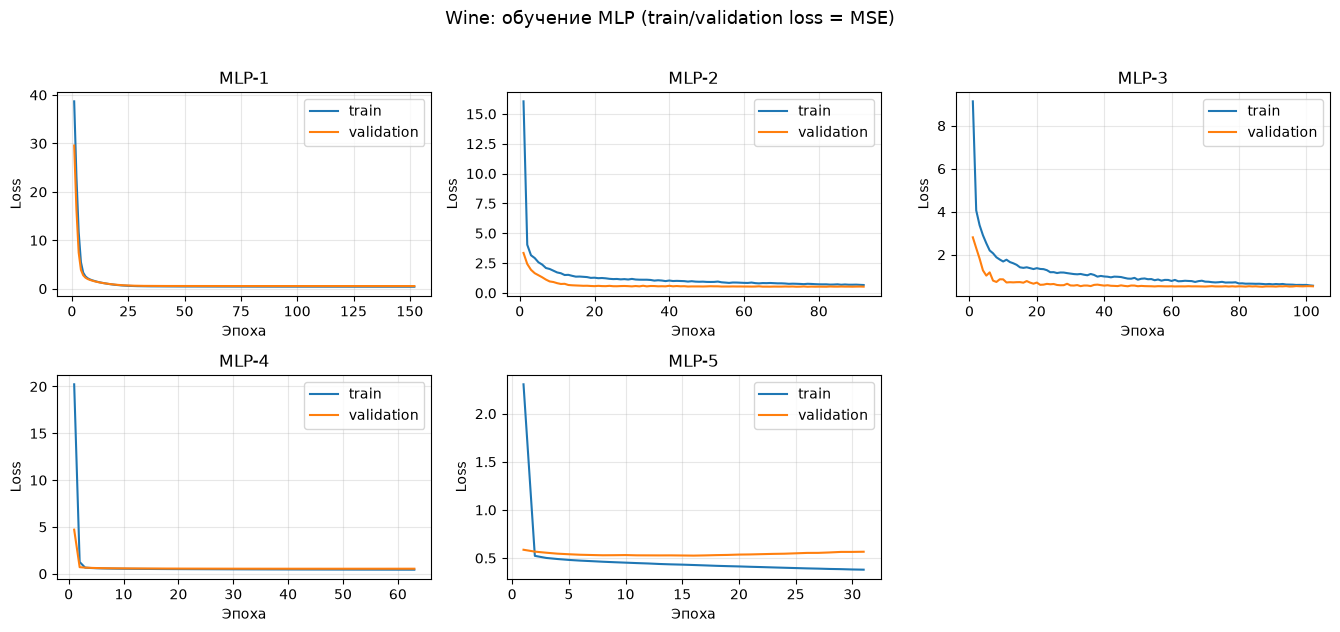

In [20]:
display_cols = ["Модель", "Эпох", "Train MSE", "Val MSE", "Val R2", "Test MSE", "Test MAE", "Test R2", "Переобучение (Val MSE − Train MSE)"]
print(reg_df[display_cols].round(4).to_string(index=False))
plot_histories(reg_hist, "Wine: обучение MLP (train/validation loss = MSE)")